In [81]:
import logging
import pandas as pd
from audio_files import GCStore, AudioExtenstion, AudioFile
from signal_treatment import (
    extract_spectral_distribution,
    plot_spectral, band_levels,
    standard_bands, plot_bands_spectrum,
    plot_bands_timeserie,
    acoustic_events,
    extract_spectrum_multiple_files
)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [82]:
logging.basicConfig(
    level=logging.WARNING,  
    format="%(asctime)s %(levelname)s %(name)s: %(message)s",
    force=True,
)
logging.getLogger("audio_files").setLevel(logging.INFO)

In [ ]:
BUCKET = "noaa-passive-bioacoustic"
FILES_PREFIX = "sefsc/audio/gomex/ef/sefsc_gomex_ef_01"
store = GCStore(bucket=BUCKET)
START_DATE = pd.Timestamp(2016, 7, 31)
END_DATE = pd.Timestamp(2016, 8, 5)

In [107]:
files = store.list_files(prefix=FILES_PREFIX)

In [108]:
files = GCStore.filter_files(
    filenames=files,
    extentions=[AudioExtenstion.FLAC],
    start_date=START_DATE,
    end_date=END_DATE)

In [103]:
aud = AudioFile(filename=files[0], store=store)

2026-11-22 16:46:51,890 INFO audio_files: GOM_EF_01_160731_115002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-07-31 11:50:02


2026-11-22 16:45:28,998 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  721 minutes


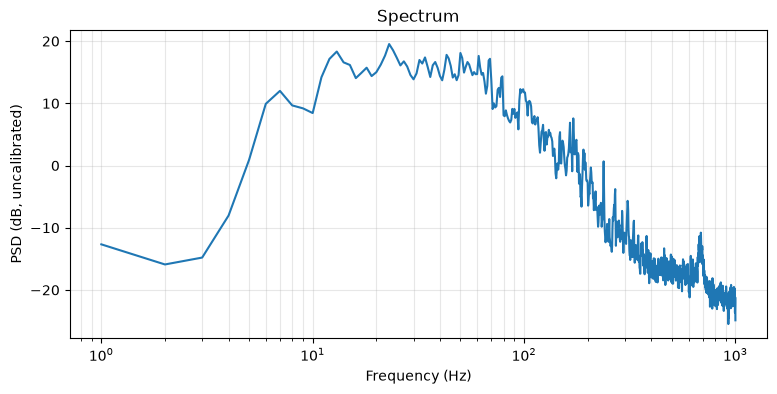

In [87]:
t0 = aud.timestamp
t1 = aud.timestamp  + pd.Timedelta(hours=12)

spectral_densities = extract_spectral_distribution(audio_file=aud, t0=t0, t1=t1)

times = spectral_densities[0]
freqs = spectral_densities[1]
psds = spectral_densities[2]
instant = 80
plot_spectral(freqs=freqs, psd=psds[instant], calibrated=False)

In [88]:
bands_def = standard_bands(fmax=freqs[-1])

bands_lvl = band_levels(
    freqs=freqs,
    psd_db=psds[instant],
    bands=bands_def)

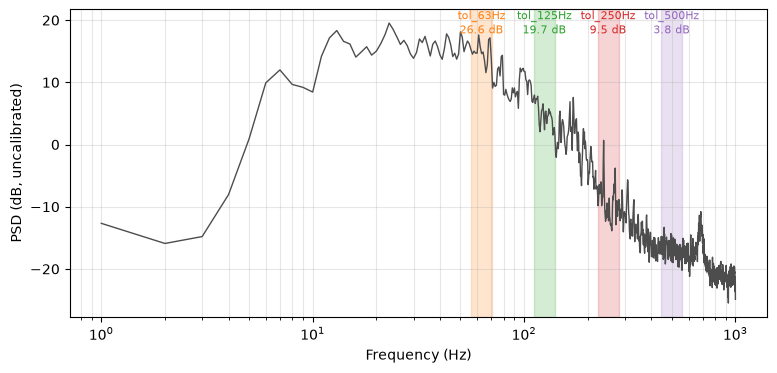

In [89]:
plot_bands_spectrum(freqs=freqs, psd=psds[instant], bands_levels=bands_lvl, bands_def=bands_def)

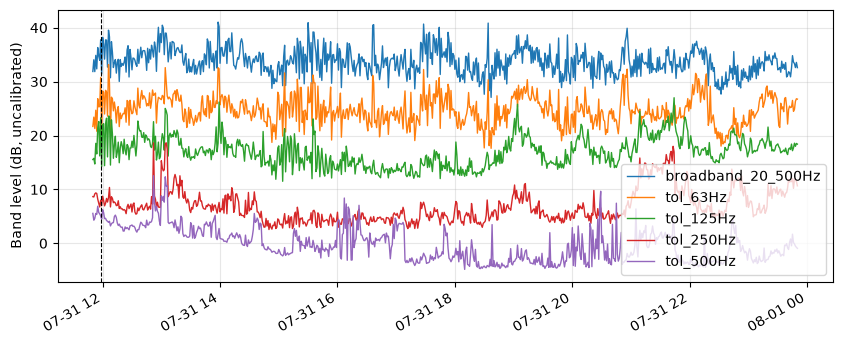

In [90]:
plot_bands_timeserie(times=times, freqs=freqs, psds=psds, bands_def=bands_def, instant=8)

In [91]:
bnd = "broadband_20_500Hz"
events, val, excess=  acoustic_events(times=times, band_level=bands_lvl[bnd], baseline_hours=1)

In [110]:
auds= [AudioFile(filename=f, store=store) for f in files]

2026-11-22 16:47:21,222 INFO audio_files: GOM_EF_01_160731_115002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-07-31 11:50:02
2026-11-22 16:47:21,999 INFO audio_files: GOM_EF_01_160803_022002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-03 02:20:02
2026-11-22 16:47:22,773 INFO audio_files: GOM_EF_01_160805_165002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-05 16:50:02
2026-11-22 16:47:23,545 INFO audio_files: GOM_EF_01_160808_072002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-08 07:20:02
2026-11-22 16:47:24,763 INFO audio_files: GOM_EF_01_160810_215002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-10 21:50:02
2026-11-22 16:47:25,941 INFO audio_files: GOM_EF_01_160813_122002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-13 12:20:02
2026-11-22 16:47:27,532 INFO audio_files: GOM_EF_01_160816

In [112]:
t0 = auds[0].timestamp
t1 = auds[len(auds)-1].timestamp
spectral_densities = extract_spectrum_multiple_files(audio_files=auds, t0=t0, t1=t1)

2026-11-22 16:47:44,121 INFO audio_files: Extracting spectra from 12 file(s) between 2016-07-31 11:50:02 and 2016-08-29 03:20:02 (10 s/min, fmax=1000 Hz)


2026-11-22 16:49:21,807 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 16:49:21,808 INFO audio_files: [1/12] GOM_EF_01_160731_115002.x.flac: 3750 minute(s), 2016-07-31 11:50:02 -> 2016-08-03 02:19:02 (97.7 s)
2026-11-22 16:50:41,441 INFO audio_files:  GOM_EF_01_160803_022002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 16:50:41,442 INFO audio_files: [2/12] GOM_EF_01_160803_022002.x.flac: 3750 minute(s), 2016-08-03 02:20:02 -> 2016-08-05 16:49:02 (79.6 s)
2026-11-22 16:51:41,052 INFO audio_files:  GOM_EF_01_160805_165002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 16:51:41,052 INFO audio_files: [3/12] GOM_EF_01_160805_165002.x.flac: 3750 minute(s), 2016-08-05 16:50:02 -> 2016-08-08 07:19:02 (59.6 s)
2026-11-22 16:52:46,445 INFO audio_files:  GOM_EF_01_160808_072002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 16:52:46,445 INFO audio_files: [4/12] GOM_EF_01_160808_072002.x.flac: 3750 minute(s), 2016-08-08 0

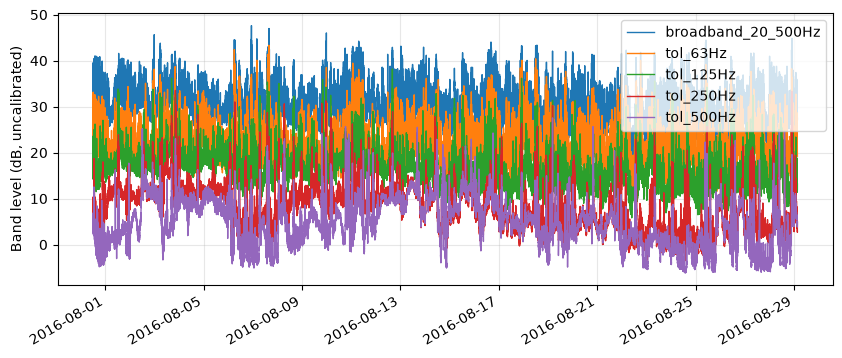

In [117]:
times = spectral_densities[0]
freqs = spectral_densities[1]
psds = spectral_densities[2]
bands_def = standard_bands(fmax=freqs[-1])
plot_bands_timeserie(times=times, freqs=freqs, psds=psds, bands_def=bands_def)

In [120]:
bands_def = standard_bands(fmax=freqs[-1])

bands_lvl = band_levels(
    freqs=freqs,
    psd_db=psds,
    bands=bands_def)

In [124]:
bnd = "tol_500Hz"
events, val, excess=  acoustic_events(times=times, band_level=bands_lvl[bnd], baseline_hours=1)

In [125]:
events

,start,end,peak_time,peak_level,peak_excess
0,2016-07-31 13:04:02,2016-07-31 13:06:02,2016-07-31 13:04:02,12.337473,8.650011
1,2016-08-01 09:38:02,2016-08-01 09:52:02,2016-08-01 09:46:02,16.268165,14.783161
2,2016-08-01 22:50:02,2016-08-01 23:03:02,2016-08-01 22:57:02,17.704321,15.072574
3,2016-08-03 05:37:02,2016-08-03 05:39:02,2016-08-03 05:39:02,17.169310,7.457170
4,2016-08-03 07:29:02,2016-08-03 07:33:02,2016-08-03 07:31:02,13.482287,10.798304
5,2016-08-03 12:16:02,2016-08-03 12:18:02,2016-08-03 12:18:02,14.237702,8.159094
6,2016-08-03 16:35:02,2016-08-03 16:38:02,2016-08-03 16:35:02,17.536703,8.676125
7,2016-08-03 20:24:02,2016-08-03 20:27:02,2016-08-03 20:26:02,23.026245,10.832790
8,2016-08-06 21:32:02,2016-08-06 21:34:02,2016-08-06 21:32:02,10.852116,11.684718
9,2016-08-07 14:07:02,2016-08-07 14:09:02,2016-08-07 14:09:02,21.499288,10.815634
